<a href="https://colab.research.google.com/github/Sn0w616/Taller-Bussiness-Analytics---AN-LISIS-DESCRIPTIVO-DE-DATOS/blob/main/Taller_ETL_Python_GonzalezCamilo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller práctico: ETL con Python
### Extracción · Transformación · Carga — Curso de Big Data

Creador de oportunidades: Camilo Andrés González López

Codigo original: Gestor del conocimiento - Edgar Mauricio Lopez Rojas

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/12RkXhLIpbqbb0Zqu352IPXRo4tMljp7h?usp=sharing)

### Marco Teórico
**Caso de estudio:** *TecnoAndes*, una tienda de tecnología con sedes en varias ciudades de Colombia, tiene sus datos dispersos en tres fuentes:

| Fuente | Formato | Contenido |
|---|---|---|
| Sistema de ventas | `ventas.csv` (separado por `;`) | 515 transacciones del 2025 |
| CRM | `clientes.json` | 15 clientes |
| Inventario | `productos.xlsx` | Catálogo de 10 productos |

La gerencia requiere un **pequeño data warehouse** para analizar las ventas por ciudad, categoría, canal y mes. Los datos llegan **sucios** de forma intencional: duplicados, fechas en varios formatos, nulos, valores negativos, textos inconsistentes y registros huérfanos.

**Objetivos de aprendizaje.** Al finalizar el taller, el estudiante estará en capacidad de:
1. Extraer datos de fuentes heterogéneas (CSV, JSON, Excel).
2. Perfilar y diagnosticar problemas de calidad de datos.
3. Aplicar transformaciones de limpieza, estandarización, integración y enriquecimiento.
4. Cargar los datos en un modelo estrella (SQLite) y validar la carga.
5. Empaquetar el proceso como un pipeline reproducible.
6. Conectar el data warehouse a **Power BI Desktop** y construir un tablero.

 **Entorno:** Google Colab (no requiere instalaciones).

### ▶️ Uso en Google Colab
1. Se guarda una copia propia mediante **Archivo → Guardar una copia en Drive**.
2. Las celdas se ejecutan **en orden** con `Shift + Enter` (o con **Entorno de ejecución → Ejecutar todas**).
3. En el panel 📁 **Archivos** (barra izquierda) pueden verse las carpetas `datos/` y `salida/` a medida que se crean.
4. ⚠️ Colab borra los archivos al cerrar la sesión; por eso, al final del taller los resultados se descargan (sección 7).

## 0. Preparación del entorno
La siguiente celda **escribe** el script `generar_datos.py` en Colab (comando mágico `%%writefile`), y la celda posterior lo ejecuta para crear la carpeta `datos/` con las tres fuentes sucias. No es necesario subir ningún archivo.

In [1]:
%%writefile generar_datos.py
"""
Genera los datos de entrada del Taller ETL, con errores de calidad intencionales.

Uso (desde la raíz del repositorio):
    python src/generar_datos.py

Crea la carpeta datos/ con: ventas.csv, clientes.json y productos.xlsx.
La semilla aleatoria es fija, por lo que los datos son siempre los mismos.
"""
import json
import os
import random

import pandas as pd

random.seed(42)
os.makedirs("datos", exist_ok=True)

# ---------- PRODUCTOS (Excel) ----------
productos = pd.DataFrame({
    "id_producto": [f"P{i:03d}" for i in range(1, 11)],
    "nombre": ["Portátil", "Mouse", "Teclado", "Monitor 24\"", "Audífonos",
               "Impresora", "Tablet", "Disco SSD 1TB", "Cámara Web", "Router WiFi"],
    "categoria": ["Computo", "Accesorios", "accesorios", "Computo", "Audio",
                  "Oficina", "Computo", "Almacenamiento", "Accesorios ", "Redes"],
    "precio_unitario": [3200000, 45000, 120000, 780000, 150000,
                        650000, 1400000, 380000, 95000, 210000],
})
productos.to_excel("datos/productos.xlsx", index=False, sheet_name="catalogo")

# ---------- CLIENTES (JSON) ----------
nombres = ["Ana Gómez", "Luis Pérez", "María Rodríguez", "Carlos López", "Laura Martínez",
           "Jorge Ramírez", "Sofía Torres", "Andrés Díaz", "Valentina Ruiz", "Felipe Castro",
           "Camila Herrera", "Santiago Moreno", "Daniela Rojas", "Juan Vargas", "Paula Ortiz"]
ciudades = ["Bogotá", "bogota", "Medellín", "MEDELLIN", " Cali", "Barranquilla",
            "Bucaramanga", "Cartagena", "Bogotá ", "Pereira"]
clientes = []
for i, n in enumerate(nombres, start=1):
    clientes.append({
        "id_cliente": i,
        "nombre": n if i % 5 else n.upper(),          # algunos en mayúsculas
        "email": None if i in (4, 11) else f"{n.split()[0].lower()}{i}@correo.com",
        "ciudad": random.choice(ciudades),
        "fecha_registro": f"2024-{random.randint(1, 12):02d}-{random.randint(1, 28):02d}",
    })
with open("datos/clientes.json", "w", encoding="utf-8") as f:
    json.dump(clientes, f, ensure_ascii=False, indent=2)

# ---------- VENTAS (CSV) ----------
formatos = ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]          # fechas inconsistentes
filas = []
for i in range(1, 501):
    fecha = pd.Timestamp("2025-01-01") + pd.Timedelta(days=random.randint(0, 364))
    cantidad = random.randint(1, 5)
    if i % 37 == 0:
        cantidad = -cantidad                                # cantidades negativas (error)
    filas.append({
        "id_venta": i,
        "fecha": fecha.strftime(random.choice(formatos)),
        "id_cliente": random.randint(1, 16),               # el 16 no existe (huérfano)
        "id_producto": random.choice(productos["id_producto"]),
        "cantidad": cantidad if i % 53 else None,          # nulos
        "descuento": random.choice(["0%", "5%", "10%", "", "15%"]),
        "canal": random.choice(["Web", "web", "Tienda", "TIENDA", "App"]),
    })
ventas = pd.DataFrame(filas)
ventas = pd.concat([ventas, ventas.sample(15, random_state=1)])   # duplicados
ventas = ventas.sample(frac=1, random_state=7)                    # desordenar
ventas.to_csv("datos/ventas.csv", index=False, sep=";", encoding="utf-8")

print("Datos generados en ./datos:")
for f in sorted(os.listdir("datos")):
    print("  -", f)

Writing generar_datos.py


In [2]:
!python generar_datos.py

import os, json, sqlite3, unicodedata, logging
import pandas as pd
pd.set_option("display.max_columns", 20)

# Vistazo a los archivos crudos, tal como llegan
!head -n 5 datos/ventas.csv
!head -n 9 datos/clientes.json

Datos generados en ./datos:
  - clientes.json
  - productos.xlsx
  - ventas.csv
id_venta;fecha;id_cliente;id_producto;cantidad;descuento;canal
490;2025-05-20;7;P003;2.0;15%;Web
430;2025/03/27;1;P004;1.0;10%;Web
83;2025-12-06;14;P003;1.0;;web
121;2025/12/19;13;P005;3.0;15%;App
[
  {
    "id_cliente": 1,
    "nombre": "Ana Gómez",
    "email": "ana1@correo.com",
    "ciudad": "bogota",
    "fecha_registro": "2024-01-24"
  },
  {


---
## 1. EXTRACCIÓN (E)
La extracción consiste en **leer los datos desde su origen sin modificarlos**. Buenas prácticas:
- Conocer el formato: separador, codificación, hoja de Excel, estructura del JSON.
- Leer los datos tal como vienen y **no limpiar todavía**: primero se diagnostica.
- Registrar cuántos registros se extrajeron, para auditar después.

In [3]:
# 1.1 CSV: atención al separador ';' y a la codificación
ventas_raw = pd.read_csv("datos/ventas.csv", sep=";", encoding="utf-8")

# 1.2 JSON: lista de objetos -> DataFrame
with open("datos/clientes.json", encoding="utf-8") as f:
    clientes_raw = pd.DataFrame(json.load(f))
# (alternativa: pd.read_json("datos/clientes.json"))

# 1.3 Excel: se indica la hoja
productos_raw = pd.read_excel("datos/productos.xlsx", sheet_name="catalogo")

for nombre, df in [("ventas", ventas_raw), ("clientes", clientes_raw), ("productos", productos_raw)]:
    print(f"{nombre:10s} -> {df.shape[0]:4d} filas, {df.shape[1]} columnas")

ventas     ->  515 filas, 7 columnas
clientes   ->   15 filas, 5 columnas
productos  ->   10 filas, 4 columnas


In [4]:
ventas_raw.head(10)

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal
0,490,2025-05-20,7,P003,2.0,15%,Web
1,430,2025/03/27,1,P004,1.0,10%,Web
2,83,2025-12-06,14,P003,1.0,NaN,web
3,121,2025/12/19,13,P005,3.0,15%,App
4,222,2025/07/29,2,P006,-3.0,0%,Tienda
5,148,16/06/2025,12,P006,-1.0,NaN,web
6,33,21/08/2025,16,P003,3.0,5%,Tienda
7,386,2025-08-19,12,P009,4.0,NaN,TIENDA
8,201,2025/09/07,10,P001,5.0,5%,TIENDA
9,482,15/11/2025,12,P010,2.0,NaN,web


### 1.4 Perfilamiento de datos (Data Profiling)
Antes de transformar, **se diagnostica**. La siguiente función resume los tipos, nulos y valores únicos de cada columna.

In [5]:
ef perfilar(df, nombre):
    print(f"=== {nombre}: {len(df)} filas | duplicados exactos: {df.duplicated().sum()} ===")
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(1),
        "únicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

perfilar(ventas_raw, "ventas")

=== ventas: 515 filas | duplicados exactos: 15 ===


,tipo,nulos,% nulos,únicos,ejemplo
id_venta,int64,0,0.0,500,490
fecha,object,0,0.0,408,2025-05-20
id_cliente,int64,0,0.0,16,7
id_producto,object,0,0.0,10,P003
cantidad,float64,9,1.7,10,2.0
descuento,object,135,26.2,4,15%
canal,object,0,0.0,5,Web


In [6]:
# Valores distintos en las columnas de texto
for col in ["canal", "descuento"]:
    print(col, "->", sorted(ventas_raw[col].dropna().unique()))
print("ciudades ->", clientes_raw["ciudad"].unique())
print("categorías ->", productos_raw["categoria"].unique())
print("cantidades negativas:", (ventas_raw["cantidad"] < 0).sum())
print("muestra de fechas:", ventas_raw["fecha"].sample(6, random_state=0).tolist())

canal -> ['App', 'TIENDA', 'Tienda', 'Web', 'web']
descuento -> ['0%', '10%', '15%', '5%']
ciudades -> ['bogota' ' Cali' 'Medellín' 'Bogotá ' 'Bucaramanga' 'Cartagena' 'Bogotá'
 'Barranquilla']
categorías -> ['Computo' 'Accesorios' 'accesorios' 'Audio' 'Oficina' 'Almacenamiento'
 'Accesorios ' 'Redes']
cantidades negativas: 13
muestra de fechas: ['2025/03/20', '2025-04-09', '2025/09/27', '29/05/2025', '2025/03/08', '22/07/2025']


Lista de **todos los problemas de calidad**:

| # | Problema | Tabla |
|---|---|---|
| 1 | Filas duplicadas | ventas |
| 2 | Fechas en 3 formatos distintos | ventas |
| 3 | Cantidades nulas y negativas | ventas |
| 4 | Descuento como texto (`"10%"`, `""`) | ventas |
| 5 | Canal con mayúsculas inconsistentes | ventas |
| 6 | Ventas de un cliente inexistente (id 16) | ventas |
| 7 | Ciudades con tildes, espacios y mayúsculas mezcladas | clientes |
| 8 | Nombres en MAYÚSCULAS, emails nulos | clientes |
| 9 | Categorías con espacios y mayúsculas | productos |

---
## 2. TRANSFORMACIÓN (T)
Es la fase más extensa. Se trabaja sobre **copias** para conservar los datos crudos (*raw*) y poder compararlos.

Tipos de transformación que se abordan:
1. **Limpieza:** duplicados, nulos y valores inválidos.
2. **Estandarización:** tipos de dato, fechas y textos.
3. **Integración:** unión de fuentes (*joins*) y verificación de la integridad referencial.
4. **Enriquecimiento:** columnas calculadas (subtotal, total, mes, etc.).

In [7]:
ventas = ventas_raw.copy()
clientes = clientes_raw.copy()
productos = productos_raw.copy()
log_calidad = []   # bitácora de las acciones realizadas, para auditoría

def registrar(paso, antes, despues):
    log_calidad.append({"paso": paso, "antes": antes, "después": despues, "afectados": antes - despues})

### 2.1 Eliminación de duplicados

In [8]:
antes = len(ventas)
ventas = ventas.drop_duplicates()                       # duplicados exactos
ventas = ventas.drop_duplicates(subset="id_venta")      # la clave de negocio debe ser única
registrar("Eliminar duplicados", antes, len(ventas))
print(f"{antes} -> {len(ventas)} filas")

515 -> 500 filas


### 2.2 Estandarización de fechas
Existen fechas como `2025-03-14`, `14/03/2025` y `2025/03/14`. Cada formato se prueba de manera explícita, lo cual es más seguro que dejar que pandas lo "adivine" (¿`03/04` corresponde a marzo o a abril?).

In [9]:
def parsear_fecha(serie):
    resultado = pd.Series(pd.NaT, index=serie.index)
    for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]:
        faltan = resultado.isna()
        resultado[faltan] = pd.to_datetime(serie[faltan], format=fmt, errors="coerce")
    return resultado

ventas["fecha"] = parsear_fecha(ventas["fecha"])
print("Fechas no reconocidas:", ventas["fecha"].isna().sum())
print("Rango:", ventas["fecha"].min().date(), "a", ventas["fecha"].max().date())

Fechas no reconocidas: 0
Rango: 2025-01-03 a 2025-12-29


### 2.3 Tratamiento de nulos y valores inválidos
Decisiones de negocio (que siempre deben quedar documentadas):
- `cantidad` nula → no es posible saber cuánto se vendió → **se descarta**.
- `cantidad` negativa → probablemente una devolución mal registrada → **se descarta**. En un caso real, estos registros se envían a una tabla de *rechazos* para su revisión.

In [10]:
antes = len(ventas)
rechazos = ventas[ventas["cantidad"].isna() | (ventas["cantidad"] <= 0)].copy()
rechazos["motivo"] = rechazos["cantidad"].apply(lambda x: "cantidad nula" if pd.isna(x) else "cantidad <= 0")

ventas = ventas.drop(rechazos.index)
ventas["cantidad"] = ventas["cantidad"].astype(int)
registrar("Cantidad nula o <= 0", antes, len(ventas))
rechazos["motivo"].value_counts()

,count
motivo,
cantidad <= 0,13
cantidad nula,9


### 2.4 Conversión de texto a número: el descuento

In [11]:
ventas["descuento"] = (
    ventas["descuento"]
      .fillna("0%")
      .replace("", "0%")
      .str.rstrip("%")
      .astype(float) / 100          # "10%" -> 0.10
)
ventas["descuento"].value_counts().sort_index()

,count
descuento,
0.00,216
0.05,75
0.10,94
0.15,93


### 2.5 Estandarización de textos
Un caso frecuente en Colombia: `Bogotá`, `bogota` y `Bogotá ` deben corresponder a la misma ciudad. El procedimiento consiste en eliminar espacios, quitar tildes para comparar y aplicar un **diccionario de mapeo** hacia el valor oficial.

In [12]:
def normalizar(texto):
    """Minúsculas, sin espacios extremos y sin tildes."""
    texto = str(texto).strip().lower()
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

mapa_ciudades = {
    "bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali", "barranquilla": "Barranquilla",
    "bucaramanga": "Bucaramanga", "cartagena": "Cartagena", "pereira": "Pereira",
}
clientes["ciudad"] = clientes["ciudad"].map(normalizar).map(mapa_ciudades)
clientes["nombre"] = clientes["nombre"].str.title()
clientes["email"] = clientes["email"].fillna("sin_email@desconocido.com")
clientes["fecha_registro"] = pd.to_datetime(clientes["fecha_registro"])

productos["categoria"] = productos["categoria"].str.strip().str.capitalize()
ventas["canal"] = ventas["canal"].str.strip().str.capitalize()

print("Ciudades:", clientes["ciudad"].unique())
print("Categorías:", productos["categoria"].unique())
print("Canales:", ventas["canal"].unique())

Ciudades: ['Bogotá' 'Cali' 'Medellín' 'Bucaramanga' 'Cartagena' 'Barranquilla']
Categorías: ['Computo' 'Accesorios' 'Audio' 'Oficina' 'Almacenamiento' 'Redes']
Canales: ['Web' 'App' 'Tienda']


### 2.6 Integridad referencial
Toda venta debe apuntar a un cliente y a un producto existentes. Para detectar registros huérfanos se utiliza un *left join* con `indicator=True`.

In [13]:
chequeo = ventas.merge(clientes[["id_cliente"]], on="id_cliente", how="left", indicator=True)
huerfanas = chequeo[chequeo["_merge"] == "left_only"]
print("Ventas con cliente inexistente:", len(huerfanas), "-> ids:", huerfanas["id_cliente"].unique())

antes = len(ventas)
h = ventas[ventas["id_cliente"].isin(huerfanas["id_cliente"])].assign(motivo="cliente inexistente")
rechazos = pd.concat([rechazos, h])
ventas = ventas.drop(h.index)
registrar("Cliente inexistente", antes, len(ventas))

assert ventas["id_producto"].isin(productos["id_producto"]).all(), "Existen productos huérfanos"

Ventas con cliente inexistente: 23 -> ids: [16]


### 2.7 Integración y enriquecimiento

In [14]:
df = (ventas
      .merge(productos, on="id_producto", how="inner")
      .merge(clientes[["id_cliente", "ciudad"]], on="id_cliente", how="inner"))

df["subtotal"] = df["cantidad"] * df["precio_unitario"]
df["valor_descuento"] = (df["subtotal"] * df["descuento"]).round(0)
df["total"] = df["subtotal"] - df["valor_descuento"]
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["dia_semana"] = df["fecha"].dt.day_name()
df = df.sort_values(["fecha", "id_venta"]).reset_index(drop=True)
df.head()

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal,nombre,categoria,precio_unitario,ciudad,subtotal,valor_descuento,total,anio,mes,dia_semana
0,241,2025-01-03,9,P004,1,0.05,App,"Monitor 24""",Computo,780000,Bogotá,780000,39000.0,741000.0,2025,1,Friday
1,419,2025-01-03,9,P002,2,0.15,Web,Mouse,Accesorios,45000,Bogotá,90000,13500.0,76500.0,2025,1,Friday
2,398,2025-01-04,13,P006,4,0.00,Tienda,Impresora,Oficina,650000,Medellín,2600000,0.0,2600000.0,2025,1,Saturday
3,156,2025-01-05,2,P010,5,0.00,Tienda,Router WiFi,Redes,210000,Cali,1050000,0.0,1050000.0,2025,1,Sunday
4,452,2025-01-05,14,P003,3,0.00,Web,Teclado,Accesorios,120000,Barranquilla,360000,0.0,360000.0,2025,1,Sunday


### 2.8 Validaciones de calidad (Data Quality Checks)
Antes de cargar, **se verifican reglas**. Si alguna falla, el pipeline debe detenerse.

In [15]:
##reglas = {
    "id_venta único":              df["id_venta"].is_unique,
    "sin fechas nulas":            df["fecha"].notna().all(),
    "cantidad > 0":                (df["cantidad"] > 0).all(),
    "descuento entre 0 y 1":       df["descuento"].between(0, 1).all(),
    "total <= subtotal":           (df["total"] <= df["subtotal"]).all(),
    "todas las ciudades mapeadas": df["ciudad"].notna().all(),
    "fechas dentro de 2025":       (df["anio"] == 2025).all(),
}
for regla, ok in reglas.items():
    print(("✅" if ok else "❌"), regla)
assert all(reglas.values()), "Falló una validación: los datos deben revisarse antes de cargar"

✅ id_venta único
✅ sin fechas nulas
✅ cantidad > 0
✅ descuento entre 0 y 1
✅ total <= subtotal
✅ todas las ciudades mapeadas
✅ fechas dentro de 2025


In [16]:
# Bitácora de calidad
pd.DataFrame(log_calidad)

,paso,antes,después,afectados
0,Eliminar duplicados,515,500,15
1,Cantidad nula o <= 0,500,478,22
2,Cliente inexistente,478,455,23


---
## 3. CARGA (L)
Los datos se cargan en un **modelo estrella** en SQLite, motor incluido en Python que no requiere instalación:

```
             dim_cliente
                 │
dim_fecha ── fact_ventas ── dim_producto
```
- **Tablas de dimensión:** describen el *quién, qué y cuándo*.
- **Tabla de hechos:** contiene las métricas (cantidad, subtotal, total) y las llaves foráneas.

Estrategias de carga: **completa** (*full load*, reemplaza todo) frente a **incremental** (solo los registros nuevos). En este taller se usa carga completa con `if_exists="replace"`.

In [17]:
os.makedirs("salida", exist_ok=True)

dim_cliente = clientes[["id_cliente", "nombre", "email", "ciudad", "fecha_registro"]]
dim_producto = productos[["id_producto", "nombre", "categoria", "precio_unitario"]]
dim_fecha = (pd.DataFrame({"fecha": pd.date_range("2025-01-01", "2025-12-31")})
             .assign(id_fecha=lambda d: d["fecha"].dt.strftime("%Y%m%d").astype(int),
                     anio=lambda d: d["fecha"].dt.year,
                     mes=lambda d: d["fecha"].dt.month,
                     trimestre=lambda d: d["fecha"].dt.quarter,
                     dia_semana=lambda d: d["fecha"].dt.day_name()))
fact_ventas = df.assign(id_fecha=df["fecha"].dt.strftime("%Y%m%d").astype(int))[
    ["id_venta", "id_fecha", "id_cliente", "id_producto", "canal",
     "cantidad", "precio_unitario", "descuento", "subtotal", "total"]]

with sqlite3.connect("salida/tecnoandes_dw.db") as con:
    for nombre, tabla in {"dim_cliente": dim_cliente, "dim_producto": dim_producto,
                          "dim_fecha": dim_fecha, "fact_ventas": fact_ventas,
                          "rechazos": rechazos}.items():
        tabla.to_sql(nombre, con, if_exists="replace", index=False)
        print(f"Cargada {nombre:13s}: {len(tabla)} filas")

# Copia plana, útil para abrir en Excel
df.to_csv("salida/ventas_limpias.csv", index=False, encoding="utf-8-sig")

Cargada dim_cliente  : 15 filas
Cargada dim_producto : 10 filas
Cargada dim_fecha    : 365 filas
Cargada fact_ventas  : 455 filas
Cargada rechazos     : 45 filas


### 3.1 Validación de la carga
Regla de oro: **lo que sale debe cuadrar con lo que entra**. Se concilian los conteos y los totales.

In [18]:
con = sqlite3.connect("salida/tecnoandes_dw.db")
filas_db = pd.read_sql("SELECT COUNT(*) AS n FROM fact_ventas", con)["n"][0]
total_db = pd.read_sql("SELECT SUM(total) AS t FROM fact_ventas", con)["t"][0]
n_rech = pd.read_sql("SELECT COUNT(*) AS n FROM rechazos", con)["n"][0]
dupl = len(ventas_raw) - ventas_raw.drop_duplicates(subset="id_venta").shape[0]

print(f"Extraídas: {len(ventas_raw)} = cargadas {filas_db} + rechazadas {n_rech} + duplicadas {dupl}"
      f" -> {'✅ cuadra' if len(ventas_raw) == filas_db + n_rech + dupl else '❌ no cuadra'}")
print(f"Total en DB = Total en pandas: {total_db == df['total'].sum()}")

Extraídas: 515 = cargadas 455 + rechazadas 45 + duplicadas 15 -> ✅ cuadra
Total en DB = Total en pandas: True


### 3.2 Consulta del data warehouse con SQL

In [19]:
consulta = """
SELECT c.ciudad, p.categoria,
       SUM(f.cantidad)              AS unidades,
       ROUND(SUM(f.total) / 1e6, 2) AS ventas_millones
FROM fact_ventas f
JOIN dim_cliente  c ON f.id_cliente  = c.id_cliente
JOIN dim_producto p ON f.id_producto = p.id_producto
GROUP BY c.ciudad, p.categoria
ORDER BY ventas_millones DESC
LIMIT 10;
"""
pd.read_sql(consulta, con)

,ciudad,categoria,unidades,ventas_millones
0,Bogotá,Computo,183,299.82
1,Bucaramanga,Computo,81,111.89
2,Cali,Computo,35,52.86
3,Medellín,Computo,39,44.96
4,Cartagena,Computo,16,42.32
5,Bogotá,Oficina,53,32.24
6,Medellín,Oficina,43,27.01
7,Bucaramanga,Oficina,36,22.36
8,Bogotá,Almacenamiento,60,21.18
9,Barranquilla,Computo,15,18.33


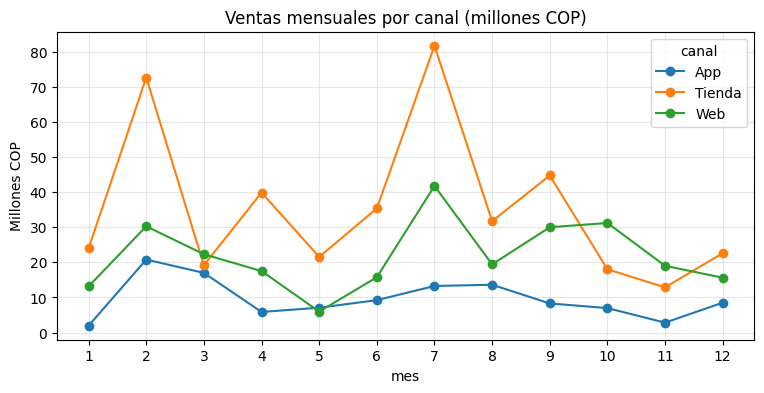

In [20]:
#ventas_mes = pd.read_sql("""
SELECT d.mes, f.canal, SUM(f.total)/1e6 AS ventas_millones
FROM fact_ventas f JOIN dim_fecha d ON f.id_fecha = d.id_fecha
GROUP BY d.mes, f.canal
""", con)

ax = (ventas_mes.pivot(index="mes", columns="canal", values="ventas_millones")
      .plot(marker="o", figsize=(9, 4), title="Ventas mensuales por canal (millones COP)"))
ax.set_xticks(range(1, 13)); ax.set_ylabel("Millones COP"); ax.grid(alpha=.3)

---
## 4. Del notebook al pipeline
En producción, el ETL no se ejecuta celda por celda: se organiza en **funciones** con *logging*, se programa (cron, Airflow, Prefect) y puede re-ejecutarse sin efectos secundarios (**idempotencia**).

La siguiente celda escribe la versión empaquetada en `etl_pipeline.py`, y la celda posterior la ejecuta tal como lo haría un servidor (`!python ...`).

In [21]:
%%writefile etl_pipeline.py
"""
Pipeline ETL - TecnoAndes (versión empaquetada del taller).

Uso (desde la raíz del repositorio, después de generar los datos):
    python src/etl_pipeline.py

Lee las fuentes de datos/, aplica las transformaciones y carga el modelo
estrella en salida/tecnoandes_dw.db (SQLite).
"""
import json
import logging
import os
import sqlite3
import unicodedata

import pandas as pd

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s",
                    datefmt="%H:%M:%S")
log = logging.getLogger("etl")

DATOS, SALIDA = "datos", "salida"
DB = os.path.join(SALIDA, "tecnoandes_dw.db")
MAPA_CIUDADES = {"bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali",
                 "barranquilla": "Barranquilla", "bucaramanga": "Bucaramanga",
                 "cartagena": "Cartagena", "pereira": "Pereira"}


# ----------------------------- EXTRACCIÓN -----------------------------
def extraer():
    ventas = pd.read_csv(f"{DATOS}/ventas.csv", sep=";", encoding="utf-8")
    with open(f"{DATOS}/clientes.json", encoding="utf-8") as f:
        clientes = pd.DataFrame(json.load(f))
    productos = pd.read_excel(f"{DATOS}/productos.xlsx", sheet_name="catalogo")
    log.info("Extraídos: ventas=%d clientes=%d productos=%d", len(ventas), len(clientes), len(productos))
    return ventas, clientes, productos


# ---------------------------- TRANSFORMACIÓN ----------------------------
def _normalizar(t):
    t = str(t).strip().lower()
    return "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")


def _parsear_fecha(s):
    r = pd.Series(pd.NaT, index=s.index)
    for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]:
        m = r.isna()
        r[m] = pd.to_datetime(s[m], format=fmt, errors="coerce")
    return r


def transformar(ventas, clientes, productos):
    v, c, p = ventas.copy(), clientes.copy(), productos.copy()

    v = v.drop_duplicates(subset="id_venta")
    v["fecha"] = _parsear_fecha(v["fecha"])

    malos = v["cantidad"].isna() | (v["cantidad"] <= 0) | v["fecha"].isna()
    rechazos = v[malos].assign(motivo="cantidad o fecha inválida")
    v = v[~malos].copy()
    v["cantidad"] = v["cantidad"].astype(int)

    v["descuento"] = v["descuento"].fillna("0%").replace("", "0%").str.rstrip("%").astype(float) / 100
    v["canal"] = v["canal"].str.strip().str.capitalize()

    c["ciudad"] = c["ciudad"].map(_normalizar).map(MAPA_CIUDADES)
    c["nombre"] = c["nombre"].str.title()
    c["email"] = c["email"].fillna("sin_email@desconocido.com")
    c["fecha_registro"] = pd.to_datetime(c["fecha_registro"])
    p["categoria"] = p["categoria"].str.strip().str.capitalize()

    huerf = ~v["id_cliente"].isin(c["id_cliente"]) | ~v["id_producto"].isin(p["id_producto"])
    rechazos = pd.concat([rechazos, v[huerf].assign(motivo="llave foránea inexistente")])
    v = v[~huerf]

    df = v.merge(p[["id_producto", "precio_unitario"]], on="id_producto")
    df["subtotal"] = df["cantidad"] * df["precio_unitario"]
    df["total"] = df["subtotal"] - (df["subtotal"] * df["descuento"]).round(0)
    df["id_fecha"] = df["fecha"].dt.strftime("%Y%m%d").astype(int)

    # Validaciones: si alguna falla, el pipeline se detiene
    assert df["id_venta"].is_unique, "id_venta duplicado"
    assert (df["total"] <= df["subtotal"]).all(), "total mayor que subtotal"
    assert c["ciudad"].notna().all(), "ciudad sin mapear"

    dim_fecha = pd.DataFrame({"fecha": pd.date_range("2025-01-01", "2025-12-31")})
    dim_fecha["id_fecha"] = dim_fecha["fecha"].dt.strftime("%Y%m%d").astype(int)
    dim_fecha["anio"] = dim_fecha["fecha"].dt.year
    dim_fecha["mes"] = dim_fecha["fecha"].dt.month
    dim_fecha["trimestre"] = dim_fecha["fecha"].dt.quarter
    dim_fecha["dia_semana"] = dim_fecha["fecha"].dt.day_name()

    fact = df[["id_venta", "id_fecha", "id_cliente", "id_producto", "canal",
               "cantidad", "precio_unitario", "descuento", "subtotal", "total"]]
    log.info("Transformado: %d ventas válidas, %d rechazos", len(fact), len(rechazos))
    return {"dim_cliente": c, "dim_producto": p, "dim_fecha": dim_fecha,
            "fact_ventas": fact, "rechazos": rechazos}


# -------------------------------- CARGA --------------------------------
def cargar(tablas):
    os.makedirs(SALIDA, exist_ok=True)
    with sqlite3.connect(DB) as con:
        for nombre, t in tablas.items():
            t.to_sql(nombre, con, if_exists="replace", index=False)
            log.info("Cargada %-12s %5d filas", nombre, len(t))


def main():
    log.info("=== Inicio ETL ===")
    cargar(transformar(*extraer()))
    log.info("=== Fin ETL: %s ===", DB)


if __name__ == "__main__":
    main()

Writing etl_pipeline.py


In [22]:
!python etl_pipeline.py

16:13:08 | INFO | === Inicio ETL ===
16:13:08 | INFO | Extraídos: ventas=515 clientes=15 productos=10
16:13:08 | INFO | Transformado: 455 ventas válidas, 45 rechazos
16:13:08 | INFO | Cargada dim_cliente     15 filas
16:13:08 | INFO | Cargada dim_producto    10 filas
16:13:08 | INFO | Cargada dim_fecha      365 filas
16:13:08 | INFO | Cargada fact_ventas    455 filas
16:13:08 | INFO | Cargada rechazos        45 filas
16:13:08 | INFO | === Fin ETL: salida/tecnoandes_dw.db ===


---
## 5. Ejercicios para entregar

### Rúbrica sugerida

| Criterio | Peso |
|---|---|
| Extracción correcta de todas las fuentes | 15% |
| Diagnóstico de calidad documentado | 15% |
| Transformaciones correctas y justificadas | 30% |
| Modelo estrella cargado y validado (conciliación) | 20% |
| Tablero en Power BI (modelo, medidas DAX, hallazgos) | 15% |
| Código limpio, comentado y reproducible | 5% |

## Ejercicio 1 — Nueva fuente de datos (Extracción)
El estudiante crea un archivo `devoluciones.csv` con las columnas `id_venta, fecha_devolucion, motivo` (mínimo 10 filas, con al menos una fecha mal escrita), lo extrae y lo perfila.

In [23]:
# EJERCICIO 1.1: Crear una fuente independiente de devoluciones

import os
import pandas as pd
import sqlite3

os.makedirs("salida/ejercicios_punto5", exist_ok=True)

devoluciones_iniciales = pd.DataFrame({
    "id_venta": [1, 5, 12, 18, 25, 32, 40, 48, 55, 63, 70, 82],
    "fecha_devolucion": [
        "2025-02-10", "15/03/2025", "2025-04-05",
        "2025-04-20", "2025-05-11", "2025-06-02",
        "2025-06-18", "2025-07-09", "2025-08-14",
        "FECHA_INVALIDA", "2025-10-05", "2025-11-12"
    ],
    "motivo": [
        "Producto defectuoso", "Pedido incorrecto",
        "Producto defectuoso", "Cambio de producto",
        "Producto incompleto", "Pedido incorrecto",
        "Cambio de producto", "Producto defectuoso",
        "Producto incompleto", "Pedido incorrecto",
        "Cambio de producto", "Producto defectuoso"
    ]
})

ruta_devoluciones = "salida/ejercicios_punto5/devoluciones.csv"

devoluciones_iniciales.to_csv(
    ruta_devoluciones,
    index=False,
    encoding="utf-8"
)

print("Archivo creado:", ruta_devoluciones)
display(devoluciones_iniciales)

Archivo creado: salida/ejercicios_punto5/devoluciones.csv


,id_venta,fecha_devolucion,motivo
0,1,2025-02-10,Producto defectuoso
1,5,15/03/2025,Pedido incorrecto
2,12,2025-04-05,Producto defectuoso
3,18,2025-04-20,Cambio de producto
4,25,2025-05-11,Producto incompleto
5,32,2025-06-02,Pedido incorrecto
6,40,2025-06-18,Cambio de producto
7,48,2025-07-09,Producto defectuoso
8,55,2025-08-14,Producto incompleto
9,63,FECHA_INVALIDA,Pedido incorrecto


In [24]:
# EJERCICIO 1.2: Extraer y perfilar devoluciones

devoluciones_raw_p5 = pd.read_csv(
    ruta_devoluciones,
    encoding="utf-8"
)

print("Dimensiones:", devoluciones_raw_p5.shape)
print("\nTipos de datos:")
print(devoluciones_raw_p5.dtypes)

print("\nValores nulos:")
print(devoluciones_raw_p5.isna().sum())

print("\nFilas duplicadas:")
print(devoluciones_raw_p5.duplicated().sum())

print("\nValores únicos por columna:")
print(devoluciones_raw_p5.nunique())

print("\nPrimeros registros:")
display(devoluciones_raw_p5.head())

Dimensiones: (12, 3)

Tipos de datos:
id_venta             int64
fecha_devolucion    object
motivo              object
dtype: object

Valores nulos:
id_venta            0
fecha_devolucion    0
motivo              0
dtype: int64

Filas duplicadas:
0

Valores únicos por columna:
id_venta            12
fecha_devolucion    12
motivo               4
dtype: int64

Primeros registros:


,id_venta,fecha_devolucion,motivo
0,1,2025-02-10,Producto defectuoso
1,5,15/03/2025,Pedido incorrecto
2,12,2025-04-05,Producto defectuoso
3,18,2025-04-20,Cambio de producto
4,25,2025-05-11,Producto incompleto


In [25]:
# EJERCICIO 1.3: Normalizar y validar las fechas

devoluciones_p5 = devoluciones_raw_p5.copy()

devoluciones_p5["fecha_devolucion_original"] = (
    devoluciones_p5["fecha_devolucion"]
)

devoluciones_p5["fecha_devolucion"] = pd.to_datetime(
    devoluciones_p5["fecha_devolucion"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

fechas_invalidas_p5 = devoluciones_p5[
    devoluciones_p5["fecha_devolucion"].isna()
]

print("Fechas inválidas:", len(fechas_invalidas_p5))
display(fechas_invalidas_p5)

print("\nDatos con fechas normalizadas:")
display(devoluciones_p5)

Fechas inválidas: 1


,id_venta,fecha_devolucion,motivo,fecha_devolucion_original
9,63,NaT,Pedido incorrecto,FECHA_INVALIDA



Datos con fechas normalizadas:


,id_venta,fecha_devolucion,motivo,fecha_devolucion_original
0,1,2025-02-10,Producto defectuoso,2025-02-10
1,5,2025-03-15,Pedido incorrecto,15/03/2025
2,12,2025-04-05,Producto defectuoso,2025-04-05
3,18,2025-04-20,Cambio de producto,2025-04-20
4,25,2025-05-11,Producto incompleto,2025-05-11
5,32,2025-06-02,Pedido incorrecto,2025-06-02
6,40,2025-06-18,Cambio de producto,2025-06-18
7,48,2025-07-09,Producto defectuoso,2025-07-09
8,55,2025-08-14,Producto incompleto,2025-08-14
9,63,NaT,Pedido incorrecto,FECHA_INVALIDA


## **Ejercicio 2 — Regla de calidad (Transformación).**
Se agrega la regla *"ningún cliente puede tener compras anteriores a su `fecha_registro`"*. El estudiante determina cuántas ventas la incumplen y justifica qué tratamiento se les debe dar.


In [26]:
# EJERCICIO 2.1: Identificar ventas anteriores al registro del cliente

ruta_db_original_p5 = "salida/tecnoandes_dw.db"

with sqlite3.connect(ruta_db_original_p5) as con:
    compras_p5 = pd.read_sql_query("""
        SELECT
            f.id_venta,
            f.id_cliente,
            c.nombre,
            c.fecha_registro,
            d.fecha AS fecha_venta,
            f.total,
            f.canal
        FROM fact_ventas AS f
        INNER JOIN dim_cliente AS c
            ON f.id_cliente = c.id_cliente
        INNER JOIN dim_fecha AS d
            ON f.id_fecha = d.id_fecha
    """, con)

compras_p5["fecha_registro"] = pd.to_datetime(
    compras_p5["fecha_registro"], errors="coerce"
)

compras_p5["fecha_venta"] = pd.to_datetime(
    compras_p5["fecha_venta"], errors="coerce"
)

compras_incumplidas_p5 = compras_p5[
    compras_p5["fecha_venta"] < compras_p5["fecha_registro"]
].copy()

print("Ventas analizadas:", len(compras_p5))
print("Ventas que incumplen la regla:", len(compras_incumplidas_p5))

display(compras_incumplidas_p5)

Ventas analizadas: 455
Ventas que incumplen la regla: 0


,id_venta,id_cliente,nombre,fecha_registro,fecha_venta,total,canal


In [27]:
# EJERCICIO 2.2: Calcular indicadores de calidad

total_analizado_p5 = len(compras_p5)
total_incumplido_p5 = len(compras_incumplidas_p5)

porcentaje_incumplimiento_p5 = (
    total_incumplido_p5 / total_analizado_p5 * 100
    if total_analizado_p5 > 0 else 0
)

print("Total de ventas analizadas:", total_analizado_p5)
print("Ventas incumplidas:", total_incumplido_p5)
print(f"Porcentaje de incumplimiento: {porcentaje_incumplimiento_p5:.2f}%")

print(
    "Valor asociado a las ventas incumplidas: "
    f"${compras_incumplidas_p5['total'].sum():,.0f} COP"
)

Total de ventas analizadas: 455
Ventas incumplidas: 0
Porcentaje de incumplimiento: 0.00%
Valor asociado a las ventas incumplidas: $0 COP


In [28]:
# EJERCICIO 2.3: Exportar los registros observados

ruta_revision_p5 = (
    "salida/ejercicios_punto5/ventas_anteriores_registro.csv"
)

compras_incumplidas_p5.to_csv(
    ruta_revision_p5,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo de revisión guardado en:", ruta_revision_p5)

Archivo de revisión guardado en: salida/ejercicios_punto5/ventas_anteriores_registro.csv


## **Ejercicio 3 — Dimensión nueva (Carga).**
Se crea `dim_canal` (`id_canal, canal, tipo`, donde el tipo es `Digital` para Web/App y `Físico` para Tienda) y se modifica `fact_ventas` para que utilice `id_canal`.

In [29]:
# EJERCICIO 3.1: Crear una base independiente para los ejercicios

ruta_db_p5 = "salida/ejercicios_punto5.db"

# Leer las tablas originales sin modificarlas
with sqlite3.connect(ruta_db_original_p5) as con_original:
    dim_cliente_p5 = pd.read_sql_query(
        "SELECT * FROM dim_cliente", con_original
    )
    dim_producto_p5 = pd.read_sql_query(
        "SELECT * FROM dim_producto", con_original
    )
    dim_fecha_p5 = pd.read_sql_query(
        "SELECT * FROM dim_fecha", con_original
    )
    fact_ventas_base_p5 = pd.read_sql_query(
        "SELECT * FROM fact_ventas", con_original
    )

print("Tablas originales leídas correctamente.")
print("Ventas originales copiadas:", len(fact_ventas_base_p5))

Tablas originales leídas correctamente.
Ventas originales copiadas: 455


In [30]:
# EJERCICIO 3.2: Crear la dimensión de canales

dim_canal_p5 = pd.DataFrame({
    "id_canal": [1, 2, 3],
    "canal": ["Web", "App", "Tienda"],
    "tipo": ["Digital", "Digital", "Físico"]
})

# Copiar la tabla de hechos para trabajar sobre ella
fact_ventas_p5 = fact_ventas_base_p5.copy()

# Normalizar el texto del canal antes de relacionarlo
fact_ventas_p5["canal"] = (
    fact_ventas_p5["canal"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.capitalize()
)

mapa_canales_p5 = {
    "Web": 1,
    "App": 2,
    "Tienda": 3
}

fact_ventas_p5["id_canal"] = (
    fact_ventas_p5["canal"].map(mapa_canales_p5)
)

# Verificar que todos los canales tengan correspondencia
canales_no_mapeados_p5 = fact_ventas_p5[
    fact_ventas_p5["id_canal"].isna()
]

print("Canales sin correspondencia:", len(canales_no_mapeados_p5))

if not canales_no_mapeados_p5.empty:
    display(canales_no_mapeados_p5[["id_venta", "canal"]])
else:
    # Reemplazar el campo canal por la llave id_canal
    fact_ventas_p5 = fact_ventas_p5.drop(columns=["canal"])

    print("\nDimensión de canales:")
    display(dim_canal_p5)

    print("\nNueva estructura de la tabla de hechos:")
    display(fact_ventas_p5.head())

Canales sin correspondencia: 0

Dimensión de canales:


,id_canal,canal,tipo
0,1,Web,Digital
1,2,App,Digital
2,3,Tienda,Físico



Nueva estructura de la tabla de hechos:


,id_venta,id_fecha,id_cliente,id_producto,cantidad,precio_unitario,descuento,subtotal,total,id_canal
0,490,20250520,7,P003,2,120000,0.15,240000,204000.0,1
1,430,20250327,1,P004,1,780000,0.10,780000,702000.0,1
2,83,20251206,14,P003,1,120000,0.00,120000,120000.0,1
3,121,20251219,13,P005,3,150000,0.15,450000,382500.0,2
4,386,20250819,12,P009,4,95000,0.00,380000,380000.0,3


In [31]:
# EJERCICIO 3.3: Cargar el modelo estrella aislado

if canales_no_mapeados_p5.empty:

    with sqlite3.connect(ruta_db_p5) as con_p5:
        dim_cliente_p5.to_sql(
            "dim_cliente", con_p5, if_exists="replace", index=False
        )

        dim_producto_p5.to_sql(
            "dim_producto", con_p5, if_exists="replace", index=False
        )

        dim_fecha_p5.to_sql(
            "dim_fecha", con_p5, if_exists="replace", index=False
        )

        dim_canal_p5.to_sql(
            "dim_canal", con_p5, if_exists="replace", index=False
        )

        fact_ventas_p5.to_sql(
            "fact_ventas", con_p5, if_exists="replace", index=False
        )

    print("Modelo cargado en:", ruta_db_p5)

    with sqlite3.connect(ruta_db_p5) as con_p5:
        tablas_p5 = pd.read_sql_query("""
            SELECT name
            FROM sqlite_master
            WHERE type = 'table'
            ORDER BY name
        """, con_p5)

    display(tablas_p5)

Modelo cargado en: salida/ejercicios_punto5.db


,name
0,dim_canal
1,dim_cliente
2,dim_fecha
3,dim_producto
4,fact_ventas


## **Ejercicio 4 — Carga incremental.**
Se modifica la carga para que, ante la llegada de ventas nuevas, solo se inserten las que aún no existen. Pista: se comparan los `id_venta` con los ya cargados y se usa `if_exists="append"`.

In [32]:
# EJERCICIO 4.1: Simular la llegada de ventas nuevas

with sqlite3.connect(ruta_db_p5) as con_p5:
    ventas_actuales_p5 = pd.read_sql_query(
        "SELECT * FROM fact_ventas", con_p5
    )

# Tomar dos registros existentes como duplicados de prueba
lote_existente_p5 = ventas_actuales_p5.head(2).copy()

# Tomar un registro como plantilla para generar dos nuevas ventas
plantilla_p5 = ventas_actuales_p5.iloc[[0]].copy()

ids_actuales_p5 = pd.to_numeric(
    ventas_actuales_p5["id_venta"], errors="coerce"
)

max_id_p5 = int(ids_actuales_p5.max())

nuevas_ventas_p5 = pd.concat(
    [plantilla_p5, plantilla_p5],
    ignore_index=True
)

nuevas_ventas_p5["id_venta"] = [
    max_id_p5 + 1,
    max_id_p5 + 2
]

# Construir un lote que contenga registros repetidos y nuevos
lote_entrante_p5 = pd.concat(
    [lote_existente_p5, nuevas_ventas_p5],
    ignore_index=True
)

print("Registros recibidos:", len(lote_entrante_p5))
display(lote_entrante_p5)

Registros recibidos: 4


,id_venta,id_fecha,id_cliente,id_producto,cantidad,precio_unitario,descuento,subtotal,total,id_canal
0,490,20250520,7,P003,2,120000,0.15,240000,204000.0,1
1,430,20250327,1,P004,1,780000,0.10,780000,702000.0,1
2,501,20250520,7,P003,2,120000,0.15,240000,204000.0,1
3,502,20250520,7,P003,2,120000,0.15,240000,204000.0,1


In [33]:
# EJERCICIO 4.2: Filtrar y cargar incrementalmente

with sqlite3.connect(ruta_db_p5) as con_p5:
    ids_cargados_p5 = pd.read_sql_query(
        "SELECT id_venta FROM fact_ventas", con_p5
    )["id_venta"]

# Comparar las llaves de negocio
lote_nuevo_p5 = lote_entrante_p5[
    ~lote_entrante_p5["id_venta"].isin(ids_cargados_p5)
].copy()

print("Registros recibidos:", len(lote_entrante_p5))
print("Registros ya existentes:", len(lote_entrante_p5) - len(lote_nuevo_p5))
print("Registros nuevos:", len(lote_nuevo_p5))

if not lote_nuevo_p5.empty:
    with sqlite3.connect(ruta_db_p5) as con_p5:
        lote_nuevo_p5.to_sql(
            "fact_ventas",
            con_p5,
            if_exists="append",
            index=False
        )

    print("Carga incremental ejecutada.")
else:
    print("No hay registros nuevos para insertar.")

Registros recibidos: 4
Registros ya existentes: 2
Registros nuevos: 2
Carga incremental ejecutada.


In [34]:
# EJERCICIO 4.3: Comprobar la cantidad de ventas y los duplicados

with sqlite3.connect(ruta_db_p5) as con_p5:
    validacion_incremental_p5 = pd.read_sql_query("""
        SELECT
            COUNT(*) AS total_registros,
            COUNT(DISTINCT id_venta) AS ventas_unicas
        FROM fact_ventas
    """, con_p5)

display(validacion_incremental_p5)

total_registros_p5 = validacion_incremental_p5.loc[0, "total_registros"]
ventas_unicas_p5 = validacion_incremental_p5.loc[0, "ventas_unicas"]

if total_registros_p5 == ventas_unicas_p5:
    print("Validación correcta: no existen identificadores duplicados.")
else:
    print("Advertencia: se encontraron identificadores duplicados.")

,total_registros,ventas_unicas
0,457,457


Validación correcta: no existen identificadores duplicados.


## **Ejercicio 5 — Análisis.**
Mediante SQL se responde: (a) los 3 clientes con mayor total comprado, (b) el mes con mayor venta y (c) el porcentaje de ventas del canal digital frente al físico.

In [35]:
# EJERCICIO 5.1: Top 3 de clientes por valor total de compras

consulta_top_clientes_p5 = """
SELECT
    c.id_cliente,
    c.nombre,
    c.ciudad,
    COUNT(DISTINCT f.id_venta) AS numero_compras,
    ROUND(SUM(f.total), 0) AS total_comprado
FROM fact_ventas AS f
INNER JOIN dim_cliente AS c
    ON f.id_cliente = c.id_cliente
GROUP BY c.id_cliente, c.nombre, c.ciudad
ORDER BY total_comprado DESC
LIMIT 3;
"""

with sqlite3.connect(ruta_db_p5) as con_p5:
    top_clientes_p5 = pd.read_sql_query(
        consulta_top_clientes_p5, con_p5
    )

display(top_clientes_p5)

,id_cliente,nombre,ciudad,numero_compras,total_comprado
0,2,Luis Pérez,Cali,33,72061250.0
1,4,Carlos López,Bogotá,32,71362250.0
2,9,Valentina Ruiz,Bogotá,34,66549500.0


In [36]:
# EJERCICIO 5.2: Identificar el mes con mayores ventas

consulta_mes_p5 = """
SELECT
    d.anio,
    d.mes,
    COUNT(DISTINCT f.id_venta) AS numero_ventas,
    ROUND(SUM(f.total), 0) AS total_ventas
FROM fact_ventas AS f
INNER JOIN dim_fecha AS d
    ON f.id_fecha = d.id_fecha
GROUP BY d.anio, d.mes
ORDER BY total_ventas DESC
LIMIT 1;
"""

with sqlite3.connect(ruta_db_p5) as con_p5:
    mes_mayor_venta_p5 = pd.read_sql_query(
        consulta_mes_p5, con_p5
    )

nombres_meses_p5 = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

if not mes_mayor_venta_p5.empty:
    mes_p5 = int(mes_mayor_venta_p5.loc[0, "mes"])
    anio_p5 = int(mes_mayor_venta_p5.loc[0, "anio"])

    print(
        "Mes con mayores ventas:",
        nombres_meses_p5[mes_p5 - 1],
        anio_p5
    )

    display(mes_mayor_venta_p5)
else:
    print("No hay ventas registradas.")

Mes con mayores ventas: Julio 2025


,anio,mes,numero_ventas,total_ventas
0,2025,7,41,136716500.0


In [37]:
# EJERCICIO 5.3: Calcular la participación de cada tipo de canal

consulta_canales_p5 = """
SELECT
    dc.tipo,
    COUNT(DISTINCT f.id_venta) AS numero_ventas,
    ROUND(SUM(f.total), 0) AS valor_ventas
FROM fact_ventas AS f
INNER JOIN dim_canal AS dc
    ON f.id_canal = dc.id_canal
GROUP BY dc.tipo
ORDER BY valor_ventas DESC;
"""

with sqlite3.connect(ruta_db_p5) as con_p5:
    ventas_por_tipo_p5 = pd.read_sql_query(
        consulta_canales_p5, con_p5
    )

total_vendido_p5 = ventas_por_tipo_p5["valor_ventas"].sum()

ventas_por_tipo_p5["porcentaje_valor"] = (
    ventas_por_tipo_p5["valor_ventas"] / total_vendido_p5 * 100
    if total_vendido_p5 > 0 else 0
)

ventas_por_tipo_p5["porcentaje_valor"] = (
    ventas_por_tipo_p5["porcentaje_valor"].round(2)
)

display(ventas_por_tipo_p5)

,tipo,numero_ventas,valor_ventas,porcentaje_valor
0,Físico,189,424259750.0,52.88
1,Digital,268,377976750.0,47.12


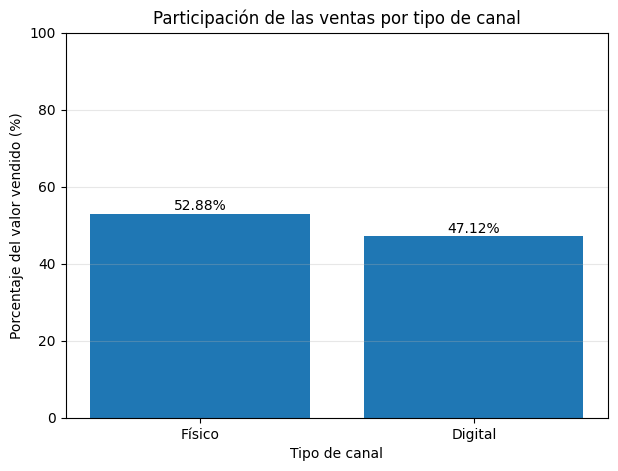

In [38]:
# EJERCICIO 5.4: Graficar el porcentaje por tipo de canal

import matplotlib.pyplot as plt

if total_vendido_p5 > 0:
    plt.figure(figsize=(7, 5))

    plt.bar(
        ventas_por_tipo_p5["tipo"],
        ventas_por_tipo_p5["porcentaje_valor"]
    )

    plt.title("Participación de las ventas por tipo de canal")
    plt.xlabel("Tipo de canal")
    plt.ylabel("Porcentaje del valor vendido (%)")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.3)

    for i, porcentaje in enumerate(
        ventas_por_tipo_p5["porcentaje_valor"]
    ):
        plt.text(i, porcentaje + 1, f"{porcentaje:.2f}%", ha="center")

    plt.show()
else:
    print("No existen ventas para representar.")

---
## 6. Del Data Warehouse a Power BI Desktop

El ETL termina cuando los datos llegan a quien los utiliza. En esta sección el **modelo estrella se conecta con Power BI Desktop** para construir un tablero.

**Ruta completa del taller:**
```
Fuentes sucias ──► Python (ETL en Colab) ──► Data Warehouse ──► Power BI (análisis)
CSV/JSON/Excel        limpiar e integrar        modelo estrella      tablero interactivo
```

**¿Por qué se exporta a Excel y no se usa directamente el `.db`?** Power BI no lee SQLite de forma nativa; requeriría instalar un driver ODBC. Un libro de Excel con **una hoja por tabla** se conecta sin instalaciones adicionales y conserva el modelo estrella.

> **Requisito:** Power BI Desktop (gratuito, disponible solo para Windows), que se descarga desde la Microsoft Store o desde [powerbi.microsoft.com/desktop](https://powerbi.microsoft.com/desktop).

### 6.1 Preparación de las tablas para Power BI

In [39]:
with sqlite3.connect("salida/tecnoandes_dw.db") as con:
    t = {n: pd.read_sql(f"SELECT * FROM {n}", con)
         for n in ["dim_cliente", "dim_producto", "dim_fecha", "fact_ventas"]}

# Ajustes orientados al usuario de negocio
meses = ["Enero","Febrero","Marzo","Abril","Mayo","Junio","Julio","Agosto",
         "Septiembre","Octubre","Noviembre","Diciembre"]
dias = {"Monday":"Lunes","Tuesday":"Martes","Wednesday":"Miércoles","Thursday":"Jueves",
        "Friday":"Viernes","Saturday":"Sábado","Sunday":"Domingo"}

f = t["dim_fecha"]
f["fecha"] = pd.to_datetime(f["fecha"]).dt.date          # tipo fecha (sin hora)
f["nombre_mes"] = f["mes"].map(lambda m: meses[m - 1])
f["mes_abrev"] = f["nombre_mes"].str[:3]
f["dia_semana"] = f["dia_semana"].map(dias)
f["num_dia_semana"] = pd.to_datetime(f["fecha"]).dt.dayofweek + 1   # 1 = Lunes
f["trimestre"] = "T" + f["trimestre"].astype(str)

t["dim_cliente"]["fecha_registro"] = pd.to_datetime(t["dim_cliente"]["fecha_registro"]).dt.date
t["dim_cliente"] = t["dim_cliente"].rename(columns={"nombre": "nombre_cliente"})
t["dim_producto"] = t["dim_producto"].rename(columns={"nombre": "nombre_producto"})
t["fact_ventas"]["tipo_canal"] = t["fact_ventas"]["canal"].map(
    {"Web": "Digital", "App": "Digital", "Tienda": "Físico"})

os.makedirs("salida/powerbi", exist_ok=True)
ruta_pbi = "salida/powerbi/modelo_tecnoandes.xlsx"
with pd.ExcelWriter(ruta_pbi) as xw:
    for nombre, tabla in t.items():
        tabla.to_excel(xw, sheet_name=nombre, index=False)
        tabla.to_csv(f"salida/powerbi/{nombre}.csv", index=False, encoding="utf-8-sig")
        print(f"{nombre:13s} {len(tabla):4d} filas  ->  {list(tabla.columns)}")

print("\nValor de control para Power BI (Ventas Totales): $", f"{t['fact_ventas']['total'].sum():,.0f}")

dim_cliente     15 filas  ->  ['id_cliente', 'nombre_cliente', 'email', 'ciudad', 'fecha_registro']
dim_producto    10 filas  ->  ['id_producto', 'nombre_producto', 'categoria', 'precio_unitario']
dim_fecha      365 filas  ->  ['fecha', 'id_fecha', 'anio', 'mes', 'trimestre', 'dia_semana', 'nombre_mes', 'mes_abrev', 'num_dia_semana']
fact_ventas    455 filas  ->  ['id_venta', 'id_fecha', 'id_cliente', 'id_producto', 'canal', 'cantidad', 'precio_unitario', 'descuento', 'subtotal', 'total', 'tipo_canal']

Valor de control para Power BI (Ventas Totales): $ 801,828,500


In [40]:
# Descarga del archivo para abrirlo en Power BI Desktop
try:
    from google.colab import files
    files.download(ruta_pbi)
except ImportError:
    print("Archivo disponible en", ruta_pbi)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 6.2 Paso a paso en Power BI Desktop

**Paso 1 — Obtención de los datos (Extracción en Power BI)**
1. En Power BI Desktop se selecciona **Inicio → Obtener datos → Libro de Excel**.
2. Se elige el archivo `modelo_tecnoandes.xlsx`.
3. En el **Navegador** se marcan las 4 hojas: `dim_cliente`, `dim_fecha`, `dim_producto` y `fact_ventas`.
4. Se pulsa **Transformar datos** (no *Cargar*) para revisarlos primero en Power Query.

**Paso 2 — Revisión en Power Query (Transformación en Power BI)**

💡 *Power Query es la herramienta ETL de Power BI: las operaciones realizadas en Python también pueden hacerse aquí.*
1. Se verifican los tipos de dato con el ícono ubicado a la izquierda de cada encabezado:
   - `fecha` y `fecha_registro` → **Fecha**.
   - `total`, `subtotal` y `precio_unitario` → **Número entero** o **Número decimal fijo**.
   - `descuento` → **Porcentaje**.
2. Si los decimales se interpretan mal (por ejemplo `0,1` frente a `0.1`), se ajusta **Archivo → Opciones → Configuración regional**, o se cambia el tipo con **Usar configuración regional → Inglés (Estados Unidos)**.
3. Se observa el panel **Pasos aplicados**, que equivale al código del notebook.
4. Se finaliza con **Inicio → Cerrar y aplicar**.

**Paso 3 — Construcción del modelo (Carga en Power BI)**
1. Se abre la **Vista de modelo** (tercer ícono de la barra izquierda).
2. Power BI suele detectar las relaciones por el nombre de las columnas. Se verifican, o se crean arrastrando la columna de una tabla a la otra, las siguientes tres relaciones:

| Desde (lado 1) | Hacia (lado *) | Cardinalidad |
|---|---|---|
| `dim_cliente[id_cliente]` | `fact_ventas[id_cliente]` | Uno a varios (1:*) |
| `dim_producto[id_producto]` | `fact_ventas[id_producto]` | Uno a varios (1:*) |
| `dim_fecha[id_fecha]` | `fact_ventas[id_fecha]` | Uno a varios (1:*) |

3. El resultado debe ser la **estrella**: `fact_ventas` en el centro y las dimensiones alrededor, con la dirección de filtro en **Única**.
4. Sobre `dim_fecha` se hace clic derecho → **Marcar como tabla de fechas** → columna `fecha`.
5. Se ordenan los meses: en la **Vista de tabla** se selecciona `nombre_mes` → **Herramientas de columna → Ordenar por columna → mes**. Lo mismo se hace con `dia_semana` usando `num_dia_semana`. Sin este paso, los meses aparecen en orden alfabético.
6. Se ocultan las llaves de `fact_ventas` (clic derecho → **Ocultar en la vista de informe**) para evitar que se usen por error.

**Paso 4 — Creación de medidas DAX**

Se selecciona la tabla `fact_ventas` → **Inicio → Nueva medida**, y se pega cada fórmula por separado (también disponibles en `powerbi/medidas.dax`):

```dax
Ventas Totales = SUM ( fact_ventas[total] )

Unidades Vendidas = SUM ( fact_ventas[cantidad] )

N° Transacciones = COUNTROWS ( fact_ventas )

Ticket Promedio = DIVIDE ( [Ventas Totales], [N° Transacciones] )

Descuento Otorgado = SUM ( fact_ventas[subtotal] ) - [Ventas Totales]

% Ventas Digitales =
DIVIDE (
    CALCULATE ( [Ventas Totales], fact_ventas[tipo_canal] = "Digital" ),
    [Ventas Totales]
)

Ventas Mes Anterior =
CALCULATE ( [Ventas Totales], DATEADD ( dim_fecha[fecha], -1, MONTH ) )

Var % vs Mes Anterior =
DIVIDE ( [Ventas Totales] - [Ventas Mes Anterior], [Ventas Mes Anterior] )
```
A cada medida se le asigna formato en **Herramientas de medidas**: `$` (moneda) para los valores y `%` para los porcentajes.

> 🔑 **Columna calculada vs. medida:** una *columna* se calcula fila por fila y se almacena en el modelo; una *medida* se calcula al momento según los filtros del tablero. Para totales y KPI se recomienda usar siempre **medidas**.

**Paso 5 — Diseño del tablero**

Diseño sugerido en una sola página titulada **"Resumen de ventas 2025"**:

| Zona | Objeto visual | Campos |
|---|---|---|
| Fila superior | 4 **Tarjetas** | `Ventas Totales`, `N° Transacciones`, `Ticket Promedio`, `% Ventas Digitales` |
| Centro izquierda | **Gráfico de líneas** | Eje: `dim_fecha[nombre_mes]` · Y: `Ventas Totales` · Leyenda: `canal` |
| Centro derecha | **Gráfico de barras** | Eje: `dim_cliente[ciudad]` · X: `Ventas Totales` |
| Abajo izquierda | **Gráfico de anillos** | Leyenda: `dim_producto[categoria]` · Valores: `Ventas Totales` |
| Abajo derecha | **Matriz** | Filas: `categoria` → `nombre_producto` · Columnas: `trimestre` · Valores: `Ventas Totales` |
| Lateral | 3 **Segmentaciones** | `ciudad`, `canal`, `nombre_mes` |

Para que el mapa ubique correctamente las ciudades, en `dim_cliente[ciudad]` se configura **Herramientas de columna → Categoría de datos → Ciudad**; luego puede agregarse un objeto visual **Mapa** con las ventas por ciudad.

**Paso 6 — Validación (el ETL no termina hasta que los datos cuadran)**

La tarjeta `Ventas Totales`, **sin filtros**, debe mostrar exactamente el valor de control: **$801.828.500** (también impreso en la celda 6.1 del notebook). Si no coincide, se revisan:
- los tipos de dato en Power Query;
- que las relaciones estén activas;
- que no existan filtros aplicados en el panel de filtros.

Finalmente, el archivo se guarda como `tecnoandes.pbix`.

### 6.3 Ejercicios en Power BI

1. **Pregunta de negocio:** ¿qué ciudad presenta el ticket promedio más alto? ¿Coincide con la ciudad que más vende? El estudiante explica la razón.
2. **Medida nueva:** se crea `Ventas Acumuladas = TOTALYTD([Ventas Totales], dim_fecha[fecha])` y se grafica por mes.
3. **Drill-down:** en la matriz se activa la jerarquía **categoría → producto** y se identifica qué producto explica la mayor parte de las ventas de *Computo*.
4. **Actualización:** se cambia `range(1, 501)` por `range(1, 2001)` en `generar_datos.py`, se ejecuta de nuevo el notebook, se reemplaza el Excel y en Power BI se pulsa **Inicio → Actualizar**. ¿Qué pasos fueron manuales? ¿Cómo se automatizaría este proceso en una empresa? (Pista: *Power BI Service*, *gateway* y actualización programada.)
5. **Entregable:** una captura del tablero y un párrafo con **tres hallazgos** dirigidos a la gerencia de TecnoAndes.

---
## 7. Descarga de resultados
Colab borra los archivos al cerrar la sesión. Existen dos opciones para conservarlos:
- **Opción A:** descargar un `.zip` con todo el resultado: la base de datos, los archivos para Power BI, el CSV limpio y los scripts.
- **Opción B:** copiarlos a Google Drive (Colab solicita autorización).

In [41]:
# Opción A: descarga de un zip
!zip -rq resultados_etl.zip salida datos generar_datos.py etl_pipeline.py
try:
    from google.colab import files
    files.download("resultados_etl.zip")
except ImportError:
    print("Fuera de Colab: el archivo quedó en resultados_etl.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Opción B: copia a Google Drive (se quitan los # para activarla)
# from google.colab import drive
# drive.mount("/content/drive")
# !mkdir -p "/content/drive/MyDrive/taller_etl"
# !cp -r salida datos *.py "/content/drive/MyDrive/taller_etl/"